# Tutorial 06: Reproduce the breakthrough validation
This notebook will guide you through the validation of the [pyDAC paper](../../README.md#how-to-cite).\
Two papers are involved here:
- **the pyDAC paper**: the model, its inputs, and the run behind its figures;
- **Zanco et al. (2022)**: the experiment and its measurements.

You will learn how to:
- run the 2D model of the pyDAC paper on the breakthrough experiment of Zanco et al., from the public release;
- read the model at the positions where the experiment measured;
- compare model and measurements, curve by curve.

The experiment of Zanco et al., on zeolite 13X:
- a column of 13X pellets, initially under nitrogen;
- fed with 12 % CO2 in N2 at 25 °C (the model takes 2.3 bar throughout: see "The flow" below);
- CO2 adsorbs, and the bed heats up where the front passes;
- CO2 leaves the column once the front reaches the outlet; the bed fills up later;
- the experiment recorded the outlet CO2 and the temperature at three radial positions in the bed.

### Overview
- **Case:** [`../cases/06_breakthrough_validation.json`](../cases/06_breakthrough_validation.json)
- **Data:** [`../data/zanco2022_13x/`](../data/zanco2022_13x/README.md), digitised from
  S. E. Zanco et al., *Chem. Eng. J.* 430 (2022) 131000
  ([doi:10.1016/j.cej.2021.131000](https://doi.org/10.1016/j.cej.2021.131000)), CC BY 4.0.
- **Runtime:** one step run of about 40 minutes on the 2D grid of the pyDAC paper (200 × 40 cells), 2 GB of memory.
  - Why so long: the grid of the pyDAC paper, 200 × 40 = 8000 cells with 5 unknowns each, plus the wall, that is 40 205 equations solved together at every time step, almost three times the largest run of tutorial 04.
  - So start it when you can leave it running. The time was measured on a workstation; on a laptop expect longer.
- **Same tutorial without a notebook:** the terminal command at the end.

### Before you start
1. Install pyDAC and select its kernel, as in [tutorial 01](01_first_steps.ipynb).
2. Check that you have about 2 GB of free memory.
3. Run the cells in order, from the top.

The results are written under `simulation_results/`, next to this notebook.

In [1]:
# Import necessary libraries
import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import pydac
from pydac.utils.postprocessing.outlet import outlet_mole_fractions
from pydac.utils.postprocessing.saved_solution import saved_solution_view

# The case file and the folder of the measured data
CASE = Path("../cases/06_breakthrough_validation.json")
DATA = Path("../data/zanco2022_13x")

# The experiment: feed CO2 and the thermocouple positions
FEED_CO2 = 0.12
PROBE_Z_M = 0.120  # thermocouple height above the inlet
PROBES_R_M = {"center": 0.0, "half_radius": 0.021, "wall": 0.0374}

## The case

The case states the experiment of Zanco et al. and the model of the pyDAC paper:
- **the column**: 20 cm long, 4.01 cm radius;
- **the sorbent**: 13X, with its competitive Sips isotherm for CO2 and N2;
- **the feed**: 12 % CO2 in N2;
- **the 2D model** with a porosity that rises towards the wall (de Klerk profile):
  - more gas flows along the wall than in the core (`wall-channeling-reduced`);
- **the inlet** (`inlet_distribution: distributed`), as in the validation of the pyDAC paper:
  - the feed is shared among the rings of the inlet face, in proportion to how easily gas flows through each of them;
  - so more of it enters near the wall.

Only the `startup` step runs: the bed starts under N2 and is fed the CO2 mixture for one hour.

In [2]:
# Build the complete case and check it
case = pydac.load_case(CASE)

# Show the main fields of the preset
preset = json.loads(CASE.read_text())["simulation"]
startup = preset["cycle"]["steps"]["startup"]
print("grid:          ", preset["grid"])
print("column:        ", preset["geometry"])
print("bed:           ", preset["bed"]["design"])
print("feed CO2:      ", startup["composition"]["co2_feed_mole_fraction"])
print("pressure [Pa]: ", startup["pressure"]["feed_pressure_Pa"])
print("duration [s]:  ", startup["horizon"]["nominal_time_s"])
print("initial solid: ", startup["composition"]["initial_solid_loadings_mol_per_kg"], "mol/kg")

grid:           {'nz': 200, 'nr': 40}
column:         {'specified_by': 'length_radius', 'length_m': 0.2, 'radius_m': 0.0401}
bed:            {'eps_b': 0.388, 'flow_model': 'wall-channeling-reduced', 'channeling': {'porosity_model': 'de_klerk', 'drag_layer_width_dp': 1.0, 'inlet_distribution': 'distributed'}, 'wall_htc_model': 'specchia_1980'}
feed CO2:       0.12
pressure [Pa]:  230000.0
duration [s]:   3600.0
initial solid:  {'CO2': 0.0, 'N2': 0.357} mol/kg


### The initial solid
- Before the run the bed holds N2, at a pressure Zanco et al. do not report.
- The pyDAC paper assumes 0.357 mol/kg of N2 and no CO2 (its SI, table of the 13X inputs).
- `initial_solid_loadings_mol_per_kg` sets exactly that:
  - one value for each species that adsorbs;
  - the same in the whole bed.
- Without it, pyDAC would start the solid in equilibrium with the initial gas, pure N2 at 2.3 bar:\
  about twice as much N2.

### The flow
- The volumetric flow is the one that gives the measured molar feed at 2.3 bar.
- Zanco et al. give 2.3 bar only as the pressure at the end of the experiment.
- The pyDAC paper explains why it is taken as 2.3 bar throughout.

## Run it

One step run (about 40 minutes).\
It prints its run folder when it starts and when it ends.

In [3]:
# Run the startup step (about 40 minutes) and print where the results are written.
# The log shows how far the step has got: % of the one hour simulated, and the simulated time.
result = pydac.run_steps(case, overwrite=True)
print(result.folder)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_06_packed_bed_1d1003bd
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_06_packed_bed_1d1003bd

------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_06_packed_bed_1d1003bd

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=time.

                                       Running Startup Step                                         
Execution mode      : solve=True (new simulation will be run)
Selected equilibrium: competitive Sips | Components: CO2, N2 | Dataset: zeolite-13x-v2-breakthrough
Selected CO2 rate equation: LDF rate
Selected N2 rate eq

## Read the model at the measured positions

The step solution `sol.pkl` holds every field at every saved time.\
Two quantities are compared with the experiment, as in the pyDAC paper:

**1. The outlet CO2 mole fraction**
- the flow-weighted (mixing-cup) average over the outlet face;
- `outlet_mole_fractions` computes it from the solution.

**2. The bed temperature at each thermocouple**
- at 12 cm from the inlet, and at r = 0, 21 and 37.4 mm;
- interpolated between the four surrounding cell centres;
- the thermocouple at 37.4 mm sits in the bed near the wall:\
  it is compared with the bed temperature, not with the temperature of the column wall.

**A safety note on `sol.pkl`**
- pyDAC saves the solution with Python's `pickle`.
- Opening a pickle file can run any code stored in it.
- So open only your own run folders, or folders from someone you trust:\
  never a `sol.pkl` downloaded from an unknown source.
- More in the guide: [Open only folders you trust](../../docs/guide/06_results.md#open-only-folders-you-trust).

In [4]:
# Load the saved solution of the startup step
with open(result.folder / "2D_mode" / "startup" / "sol.pkl", "rb") as stream:
    solution = pickle.load(stream)
view = saved_solution_view(solution)
extra = solution["extra"]

# Times, cell centres and the bed temperature field
t_model = np.asarray(view.time_s, dtype=float)
z = np.asarray(extra["z_c"]) * extra["L_bed"]  # axial cell centres [m]
r = np.asarray(extra["r_c"]) * extra["R_bed"]  # radial cell centres [m]
T_bed = view.field("T_bed")                     # (nz, nr, nt) [K]


def bracket(centres, x):
    # The two cell centres around x and the weight of the upper one.
    upper = int(np.clip(np.searchsorted(centres, x), 1, centres.size - 1))
    weight = (x - centres[upper - 1]) / (centres[upper] - centres[upper - 1])
    return upper - 1, upper, float(np.clip(weight, 0.0, 1.0))


def probe(field, z_m, r_m):
    # Bilinear interpolation of a (nz, nr, nt) field at one position.
    z0, z1, wz = bracket(z, z_m)
    r0, r1, wr = bracket(r, r_m)
    low = field[z0, r0] * (1 - wr) + field[z0, r1] * wr
    high = field[z1, r0] * (1 - wr) + field[z1, r1] * wr
    return low * (1 - wz) + high * wz


# The model curves: outlet CO2, and the bed temperature at each thermocouple
y_model = outlet_mole_fractions(solution)["CO2"]
T_model = {name: probe(T_bed, PROBE_Z_M, radius) for name, radius in PROBES_R_M.items()}
print(f"{t_model.size} saved times, 0 to {t_model[-1]:.0f} s")

1000 saved times, 0 to 3600 s


## The measurements

Four CSV files, time in minutes:
- the outlet CO2 mole fraction;
- the three temperatures, in kelvin.

Their [README](../data/zanco2022_13x/README.md) gives the figure of Zanco et al. each comes from, and how well it can be read:
- temperatures: about ±2 K before 3 min, and ±0.5 K after 4.6 min;
- on the steep rise the reading error is in time: about ±3 s.

In [5]:
# Read the measured curves: columns = time [min], value
co2 = np.loadtxt(DATA / "co2.csv", delimiter=",", skiprows=1)
measured_T = {name: np.loadtxt(DATA / f"{name}.csv", delimiter=",", skiprows=1) for name in PROBES_R_M}

# How many points each curve has, and over which times
print(f"outlet CO2: {len(co2)} points, {co2[0, 0]} to {co2[-1, 0]} min")
for name, data in measured_T.items():
    print(f"T {name:11s}: {len(data)} points, {data[0, 0]} to {data[-1, 0]} min")

outlet CO2: 594 points, 0.7 to 60.0 min
T center     : 901 points, 0.0 to 45.0 min
T half_radius: 901 points, 0.0 to 45.0 min
T wall       : 901 points, 0.0 to 45.0 min


## Model and experiment

Two figures, with the same layout as in the pyDAC paper:
- **the bed temperature** at the three thermocouples, one panel each;
- **the outlet composition**: CO2 on the left axis, N2 on the right one.

How to read them:
- **lines**: the model, at the nominal position of each probe;
- **points**: the experiment, a few of the digitised points; the temperatures with their reading uncertainty (data README);
- **shaded band**: the model within ±1 mm of the probe position.
  - The experiment does not report this tolerance: ±1 mm is our assumption, to show how sensitive each probe is.

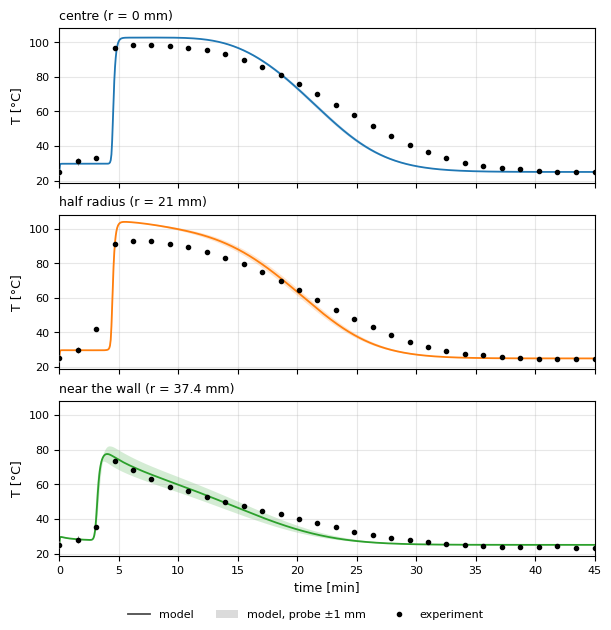

In [6]:
# A small style of its own (the step plots of a run change matplotlib's defaults)
STYLE = {"font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8,
         "ytick.labelsize": 8, "axes.linewidth": 0.8}
TITLES = {"center": "centre", "half_radius": "half radius", "wall": "near the wall"}
POSITION_M = 0.001  # assumed tolerance of each thermocouple position, radial and axial (not reported)


def spread_points(data, n):
    # n measured points spread over the whole curve, so that the markers stay readable
    return data[np.linspace(0, len(data) - 1, n, dtype=int)]


def reading_error(t_min):
    # Reading uncertainty of the digitised temperatures (data README):
    # ±2 K before 2.9 min, ±0.5 K after 4.6 min; on the steep rise in between, ±0.05 min in time
    on_rise = (t_min >= 2.9) & (t_min <= 4.6)
    return np.where(on_rise, 0.05, 0.0), np.where(t_min < 2.9, 2.0, np.where(on_rise, 0.0, 0.5))


with plt.rc_context(STYLE):
    fig, axes = plt.subplots(3, 1, figsize=(6, 6.2), sharex=True, sharey=True, constrained_layout=True)
    for k, (ax, (name, radius)) in enumerate(zip(axes, PROBES_R_M.items())):
        color = f"C{k}"

        # Shaded: the lowest and highest model reading within ±1 mm of the probe
        heights = np.linspace(PROBE_Z_M - POSITION_M, PROBE_Z_M + POSITION_M, 9)
        radii = np.unique(np.clip(np.linspace(radius - POSITION_M, radius + POSITION_M, 9), 0.0, extra["R_bed"]))
        box = np.array([probe(T_bed, z_m, r_m) for z_m in heights for r_m in radii]) - 273.15
        ax.fill_between(t_model / 60, box.min(axis=0), box.max(axis=0), color=color, alpha=0.2, linewidth=0)

        # Line: the model at the nominal position; black points: the experiment, with its reading uncertainty
        ax.plot(t_model / 60, T_model[name] - 273.15, color=color, linewidth=1.3)
        points = spread_points(measured_T[name], 30)
        xerr, yerr = reading_error(points[:, 0])
        ax.errorbar(points[:, 0], points[:, 1] - 273.15, xerr=xerr, yerr=yerr, fmt="o", ms=3, color="black",
                    ecolor="0.5", elinewidth=0.7, capsize=0, zorder=4)

        ax.set_title(f"{TITLES[name]} (r = {radius * 1000:g} mm)", loc="left", fontsize=9)
        ax.grid(alpha=0.3)
        ax.set_ylabel("T [°C]")
    axes[-1].set_xlabel("time [min]")
    axes[-1].set_xlim(0, 45)

    # One legend for the three panels, below them
    fig.legend(handles=[
        Line2D([], [], color="0.3", linewidth=1.3, label="model"),
        Patch(facecolor="0.3", alpha=0.2, label=f"model, probe ±{POSITION_M * 1000:g} mm"),
        Line2D([], [], marker="o", ls="none", ms=3, color="black", label="experiment"),
    ], loc="outside lower center", ncol=3, frameon=False)
    plt.show()

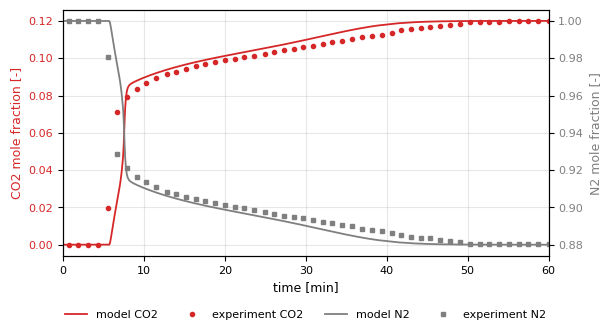

In [7]:
# Outlet composition: CO2 on the left axis, N2 on the right one.
# The feed has only CO2 and N2, so y_N2 = 1 - y_CO2: the right axis spans the complement of the left one.
measured = spread_points(co2, 50)
with plt.rc_context(STYLE):
    fig, ax_co2 = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
    ax_n2 = ax_co2.twinx()
    handles = []
    for ax, model, experiment, color, marker, gas in [
        (ax_co2, y_model, measured[:, 1], "C3", "o", "CO2"),
        (ax_n2, 1 - y_model, 1 - measured[:, 1], "C7", "s", "N2"),
    ]:
        ax.plot(t_model / 60, model, color=color, linewidth=1.3)
        ax.plot(measured[:, 0], experiment, ls="none", marker=marker, ms=3, color=color)
        ax.set_ylabel(f"{gas} mole fraction [-]", color=color)
        ax.tick_params(axis="y", labelcolor=color)
        handles += [Line2D([], [], color=color, linewidth=1.3, label=f"model {gas}"),
                    Line2D([], [], ls="none", marker=marker, ms=3, color=color, label=f"experiment {gas}")]
    pad = 0.05 * FEED_CO2
    ax_co2.set_ylim(-pad, FEED_CO2 + pad)
    ax_n2.set_ylim(1 - FEED_CO2 - pad, 1 + pad)
    ax_co2.grid(alpha=0.3)
    ax_co2.set_xlabel("time [min]")
    ax_co2.set_xlim(0, 60)
    fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False)
    plt.show()

The model follows the measured curves:
- **Outlet**: free of CO2 for about six minutes.
  - Then CO2 breaks through and rises towards the feed value.
- **Probes**: the temperature rises sharply as the front passes.
  - Then it falls back, as the bed cools through the wall.
- **Before the front** the bed warms by a few kelvin, in model and experiment alike.
  - The solid starts with less N2 than it holds in equilibrium with N2 at 2.3 bar.
  - It takes it up, and releases its heat.

The figure also shows where model and measurement differ (the same differences the pyDAC paper discusses):
- the model cools faster: from about 20 minutes on it is colder than the measurement, by up to 15 K at the centre (around 50 °C);
- at half radius it predicts a plateau as high as at the centre, where the measured one is about 5 K lower.

## From the terminal

The same run, from the folder of this notebook:

```bash
pydac steps --config ../cases/06_breakthrough_validation.json --overwrite
```

- It writes the same run folder: the case is the same.
- The comparison with the measurements is the Python above: run it in this notebook.

**Previous:** [Tutorial 05: An optimization campaign](05_nsga2_trial.ipynb).\
**Next:** [Tutorial 07: Your own isotherm](07_new_isotherm.ipynb).